# P2 — Robustez e interpretación (integrante 3)

Este notebook complementa los modelos de integrante 2. No busca el mejor clasificador, sino responder tres preguntas sobre el problema:

Las hipótesis se formularon en P1 (sección 6 de `eda/01_eda.ipynb`) y se contrastan aquí tal como se plantearon:

- **H1.** La tasa de comisión reciente es el predictor dominante, dada la persistencia observada en series de esta naturaleza.
- **H2.** Los atributos de actividad de la red (número de transacciones y comisiones totales) aportan una mejora marginal sobre H1, menor que la contribución de la propia tasa.
- **H3.** El desempeño se degrada en los episodios de mayor variación del nivel de comisiones, que son aquellos en los que una estimación correcta resulta más valiosa.

Se reutiliza sin cambios el protocolo de `../integrante2/PROTOCOLO.md`: mismo dataset (SHA-256 verificado), target con umbral móvil P75 de 1008 bloques, particiones cronológicas 70/15/15, `gap` de 1008 bloques y las 33 características causales. **El test no se utiliza en ningún paso.** Todas las cifras provienen de la validación cruzada temporal dentro de entrenamiento o de la partición de validación (mayo de 2021 a agosto de 2022).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / 'src'))

import pandas as pd
from IPython.display import Image, display

import robustez

RESULTADOS = Path.cwd().parent / 'results'
FIGURAS = RESULTADOS / 'figures'
REENTRENAR = False  # True para repetir todo el experimento (unos 3 minutos)

if REENTRENAR or not (RESULTADOS / 'manifest.json').exists():
    robustez.run()

leer = lambda nombre: pd.read_csv(RESULTADOS / f'{nombre}.csv')
pd.set_option('display.precision', 4)

## 1. Grupos de variables

Las 33 características se agrupan según la información que representan. No se crea ninguna variable nueva.

| Conjunto | Variables | Contenido |
|---|---|---|
| **A0** — tasa actual | 3 | `median_fee_rate`, `umbral_local`, `fee_relativa` |
| **A** — comisiones | 16 | A0 + tasa promedio, rango de tasas, razón promedio/mediana, rezagos (1, 6, 144) y medias y desviaciones móviles (6, 144, 1008) |
| **B** — comisiones + actividad | 29 | A + comisiones totales, tamaño, transacciones, entradas, salidas, valor transferido, dificultad, razones por transacción, ocupación relativa e intervalo entre bloques |
| **C** — todas | 33 | B + hora del día y día de la semana (seno y coseno) |

Siguiendo la redacción de H2 en P1, `total_fees` se considera actividad de la red: depende tanto de la tasa como del número y tamaño de las transacciones del bloque.

In [2]:
pd.Series({nombre: len(cols) for nombre, cols in robustez.CONJUNTOS.items()}, name='n_variables')

A0_tasa_actual             3
A_comisiones              16
B_comisiones_actividad    29
C_todas                   33
Name: n_variables, dtype: int64

## 2. Modelo y protocolo del ablation

Se usa un único `HistGradientBoostingClassifier` sencillo para los cuatro conjuntos, de modo que la única diferencia entre ellos sean las variables:

- `max_iter=150`, `max_leaf_nodes=15`, `learning_rate=0.1`, `min_samples_leaf=80`, `l2_regularization=1.0`, `early_stopping=False`, semilla 42.
- Mismo imputador por mediana, ajustado solo en cada entrenamiento (función `estimator` de integrante 2).
- Mismos tres folds de ventana expansiva con `gap=1008` que integrante 2.
- Umbral de decisión elegido con las probabilidades fuera de fold, con la misma malla 0,10–0,90 y el mismo criterio de desempate.
- Reajuste final con las primeras 292 096 filas de entrenamiento y una sola evaluación en validación.

La configuración no se optimizó: el objetivo es comparar conjuntos de variables en igualdad de condiciones. Como control, el conjunto C (las 33 variables) obtiene en validación un F1 de 0,568, cercano al 0,571 del HistGradientBoosting de integrante 2, que sí pasó por búsqueda de hiperparámetros.

La **persistencia** (predecir para el bloque siguiente la clase del bloque actual) se incluye solo como referencia. Su implementación oficial corresponde a integrante 1.

## 3. Ablation: ¿qué información aporta cada grupo? (H1 y H2)

In [3]:
resumen = leer('ablation_resumen')
resumen[['conjunto', 'n_variables', 'cv_ap_media', 'cv_ap_std', 'val_average_precision',
         'val_f1', 'val_precision', 'val_recall', 'val_roc_auc', 'umbral']]

,conjunto,n_variables,cv_ap_media,cv_ap_std,val_average_precision,val_f1,val_precision,val_recall,val_roc_auc,umbral
0,A0_tasa_actual,3,0.6495,0.0566,0.5357,0.5387,0.5383,0.5391,0.7494,0.275
1,A_comisiones,16,0.7327,0.0517,0.6192,0.5665,0.5501,0.5839,0.8151,0.300
2,B_comisiones_actividad,29,0.7465,0.0463,0.6316,0.5727,0.5729,0.5726,0.8199,0.325
3,C_todas,33,0.7452,0.0499,0.6309,0.5677,0.5847,0.5517,0.8221,0.350
4,persistencia,0,NaN,NaN,0.3904,0.5400,0.5400,0.5400,NaN,NaN


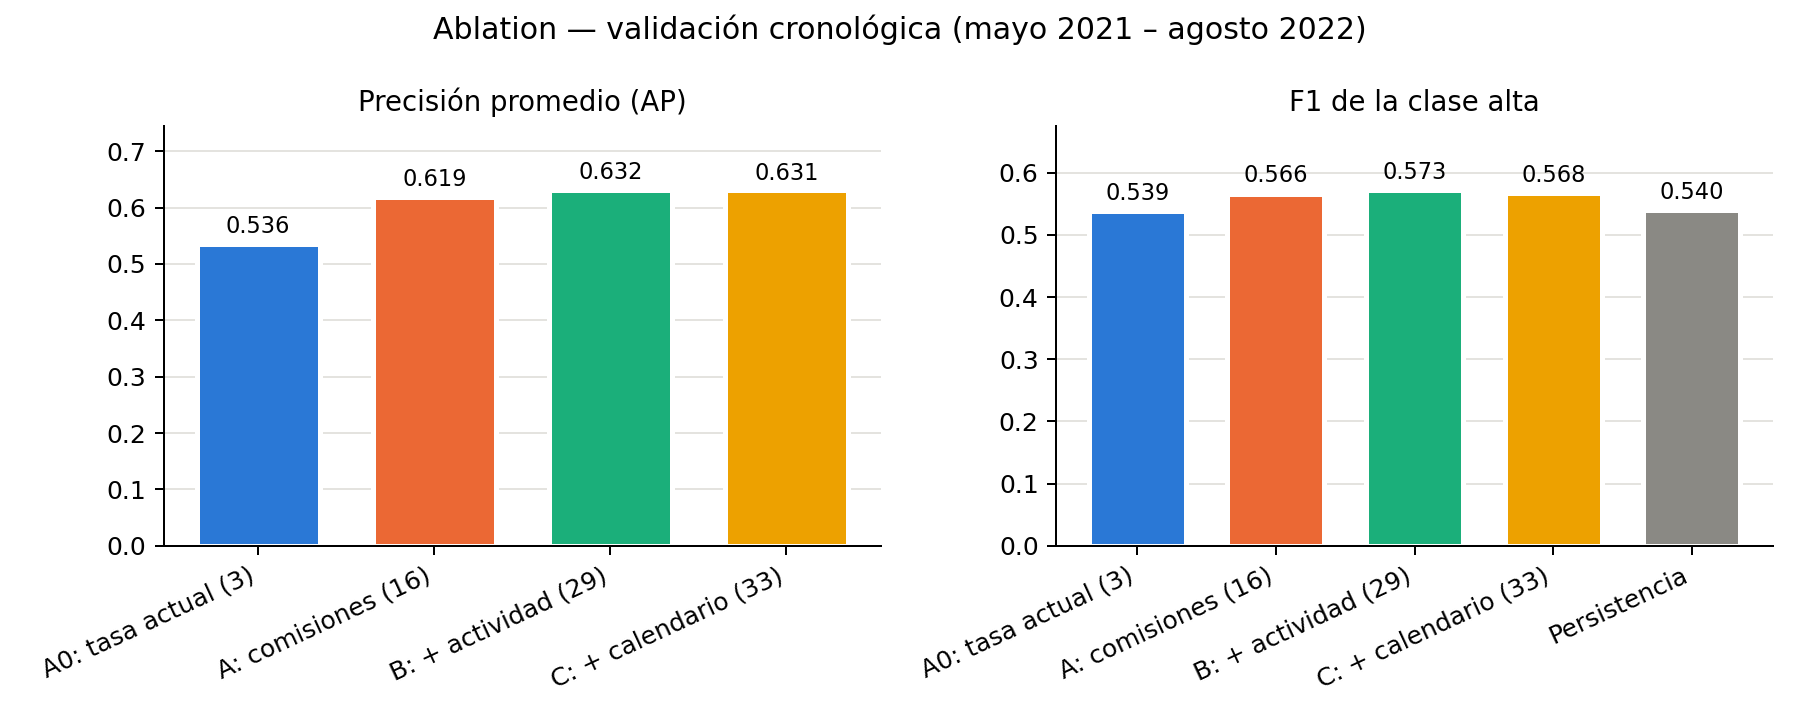

In [4]:
display(Image(FIGURAS / 'ablation_validacion.png'))

Para comparar conjuntos se prioriza la **precisión promedio (AP)**, que no depende del umbral de decisión. El F1 depende además del umbral elegido en los folds y es más ruidoso.

La persistencia solo produce etiquetas 0/1, por lo que su AP no es comparable con la de un modelo probabilístico y no se muestra en el panel izquierdo.

Como los bloques consecutivos están fuertemente correlacionados, las diferencias se evalúan con un **bootstrap por bloques móviles** de 1008 bloques (una semana) sobre validación: 1000 remuestreos emparejados, con los mismos índices para ambos modelos.

In [5]:
leer('ablation_bootstrap')

,comparacion,metrica,diferencia,ic95_inf,ic95_sup,prop_boot_mayor_0
0,A_comisiones - A0_tasa_actual,average_precision,0.0835,0.0700,0.0948,1.000
1,A_comisiones - A0_tasa_actual,f1,0.0278,0.0200,0.0360,1.000
2,B_comisiones_actividad - A_comisiones,average_precision,0.0124,0.0083,0.0167,1.000
3,B_comisiones_actividad - A_comisiones,f1,0.0063,0.0014,0.0111,0.998
4,C_todas - B_comisiones_actividad,average_precision,-0.0007,-0.0059,0.0042,0.404
5,C_todas - B_comisiones_actividad,f1,-0.0050,-0.0107,0.0008,0.044
6,A0_tasa_actual - persistencia,average_precision,0.1453,0.1301,0.1595,1.000
7,A0_tasa_actual - persistencia,f1,-0.0013,-0.0023,-0.0003,0.001


**Interpretación.**

- **H1 — se confirma, con un matiz.** La tasa actual por sí sola (A0) ya alcanza un F1 de 0,539, prácticamente igual al de la persistencia (0,540). Con solo tres variables, el modelo reproduce la regla «si el bloque actual está por encima de su umbral, el siguiente también lo estará». La tasa reciente es la base de toda la capacidad predictiva, pero el estado actual por sí solo no supera a la regla trivial.
- **La historia de las comisiones es lo que aporta valor.** Pasar de A0 a A (rezagos, medias y desviaciones móviles, rango y dispersión de las tasas) sube la AP de 0,536 a 0,619 (+0,084; IC 95 % [0,070; 0,095]). Es la mayor mejora del estudio.
- **H2 — se confirma: la mejora de la actividad de la red es real pero marginal.** Añadir las variables de actividad, incluidas las comisiones totales (B), sube la AP en 0,012 (IC 95 % [0,008; 0,017]) y el F1 en 0,006 (IC [0,001; 0,011]). La mejora es estadísticamente detectable, pero unas siete veces menor que la aportación de la historia de comisiones.
- **El calendario no aporta.** La diferencia C − B es nula en AP (−0,001; IC [−0,006; 0,004]) y ligeramente negativa en F1. La hora y el día de la semana no añaden información una vez conocidas las comisiones recientes.

Los folds de entrenamiento muestran el mismo orden (A0 < A < B ≈ C en AP) en los tres periodos, de modo que la conclusión no depende de un solo tramo temporal.

In [6]:
leer('ablation_folds').pivot(index='conjunto', columns='fold', values='average_precision')

fold,1,2,3
conjunto,,,
A0_tasa_actual,0.5911,0.6532,0.7041
A_comisiones,0.6755,0.7468,0.7759
B_comisiones_actividad,0.6955,0.7581,0.7859
C_todas,0.6892,0.7613,0.7850
persistencia,0.4435,0.4914,0.5262


## 4. Rendimiento por periodos y según la volatilidad (H3)

In [7]:
trimestre = leer('segmentos_trimestre')
f1_trimestre = trimestre.pivot(index='conjunto', columns='segmento', values='f1')
f1_trimestre.loc['prevalencia'] = trimestre.drop_duplicates('segmento').set_index('segmento')['prevalencia']
f1_trimestre

segmento,2021Q2,2021Q3,2021Q4,2022Q1,2022Q2,2022Q3
conjunto,,,,,,
A0_tasa_actual,0.6139,0.5090,0.5580,0.5031,0.5552,0.5346
A_comisiones,0.6301,0.5338,0.5837,0.5234,0.5895,0.5673
B_comisiones_actividad,0.6445,0.5325,0.5924,0.5344,0.5996,0.5678
C_todas,0.6404,0.5307,0.5925,0.5190,0.5915,0.5646
persistencia,0.6201,0.5109,0.5595,0.5038,0.5550,0.5352
prevalencia,0.2170,0.1931,0.2321,0.1915,0.2267,0.2549


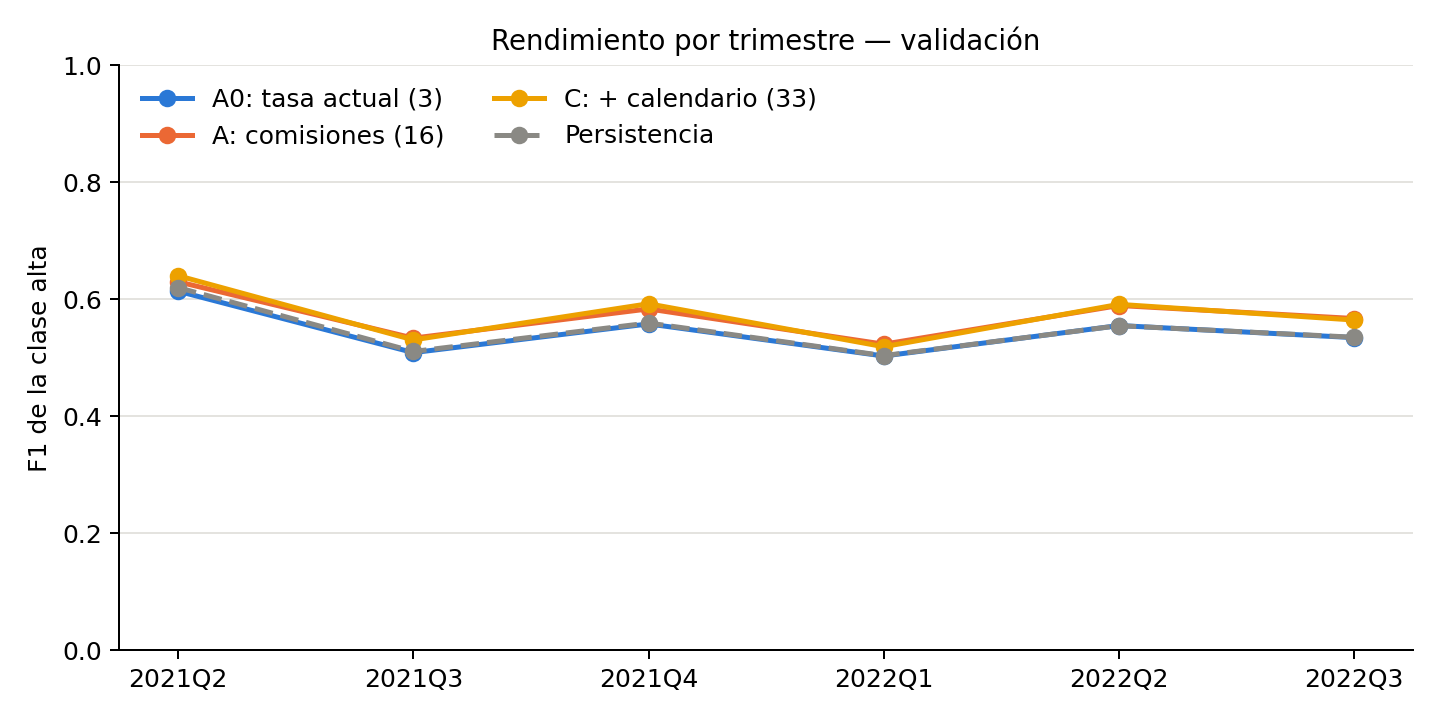

In [8]:
display(Image(FIGURAS / 'f1_por_trimestre.png'))

Entre trimestres, el F1 varía entre 0,50 y 0,64. Las oscilaciones son **comunes a todos los métodos, incluida la persistencia**, y siguen a la prevalencia de la clase alta: los trimestres con menos bloques «altos» (2021T3 y 2022T1, alrededor del 19 %) son los de menor F1. La ventaja de los modelos con historia de comisiones sobre la persistencia es positiva en todos los trimestres (entre +0,01 y +0,04 de F1). No hay un periodo donde el modelo colapse.

Para H3, la volatilidad reciente se mide con el coeficiente de variación de las últimas 144 tasas (un día), que solo usa información disponible en el bloque actual. Los terciles se fijan con entrenamiento y luego se aplican a validación.

In [9]:
volatilidad = leer('segmentos_volatilidad')
volatilidad.pivot(index='conjunto', columns='segmento', values=['f1', 'average_precision', 'prevalencia']) \
    .reindex(columns=['baja', 'media', 'alta'], level=1)

f1                 average_precision          \
segmento                  baja   media    alta              baja   media   
conjunto                                                                   
A0_tasa_actual          0.5344  0.5519  0.5096            0.5446  0.5489   
A_comisiones            0.5603  0.5790  0.5502            0.6118  0.6339   
B_comisiones_actividad  0.5676  0.5859  0.5465            0.6276  0.6469   
C_todas                 0.5655  0.5754  0.5481            0.6286  0.6428   
persistencia            0.5361  0.5522  0.5130            0.3871  0.4091   

                               prevalencia                  
segmento                  alta        baja   media    alta  
conjunto                                                    
A0_tasa_actual          0.4777      0.2144  0.2332  0.1596  
A_comisiones            0.5989      0.2144  0.2332  0.1596  
B_comisiones_actividad  0.5949      0.2144  0.2332  0.1596  
C_todas                 0.5945      0.2144  0.2332  0.1596  
persistencia            0.3403      0.2144  0.2332  0.1596

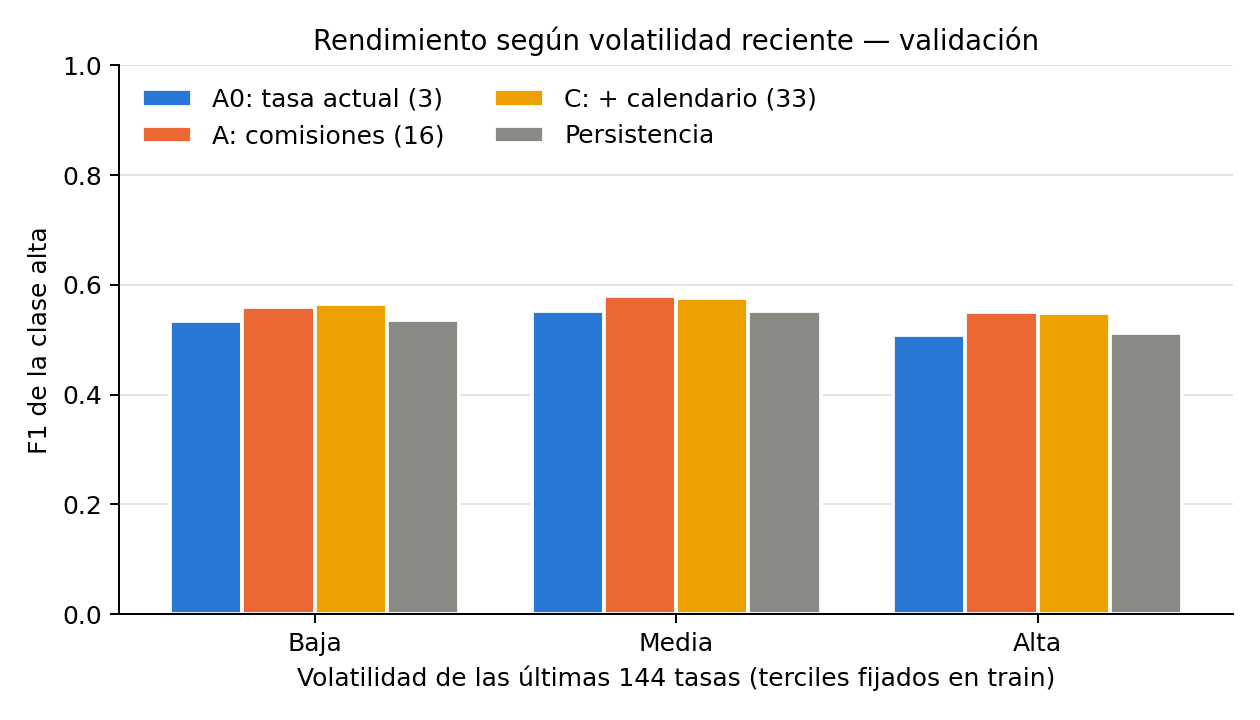

In [10]:
display(Image(FIGURAS / 'f1_por_volatilidad.png'))

**Interpretación de H3 — se confirma parcialmente.** En el tercil de mayor volatilidad, el F1 del modelo C baja a 0,548 (frente a 0,566 y 0,575) y la AP a 0,595 (frente a 0,629 y 0,643). La degradación existe pero es moderada, y parte de ella se explica porque en ese tramo hay menos positivos (16 % frente a 21–23 %), lo que reduce el F1 de forma mecánica.

Validación es un periodo relativamente tranquilo: solo 6809 bloques (11 %) caen en el tercil de alta volatilidad definido con entrenamiento. Por eso esta conclusión se apoya en una muestra pequeña de episodios turbulentos.

## 5. Análisis de errores

In [11]:
leer('errores_resumen')

,conjunto,tasa_error,p_error_dado_error_previo,falsos_positivos,falsos_negativos
0,C_todas,0.1804,0.4009,5286,6046
1,A_comisiones,0.1919,0.4401,6441,5612
2,persistencia,0.1975,0.4529,6203,6204


In [12]:
transicion = leer('errores_transicion')
n = transicion.drop_duplicates('transicion').set_index('transicion')['n']
display(transicion.pivot(index='transicion', columns='conjunto', values='tasa_error').join(n))

inicios = n['0→1 inicio de alza']
print(f"Bloques en transición: {(inicios + n['1→0 fin de alza']) / n.sum():.1%}")
print(f"Duración media de un episodio de clase alta: {(inicios + n['1→1 alta estable']) / inicios:.2f} bloques")

,A_comisiones,C_todas,persistencia,n
transicion,,,,
0→0 baja estable,0.0434,0.0352,0.0,43118
0→1 inicio de alza,0.8285,0.8557,1.0,6204
1→0 fin de alza,0.7364,0.6073,1.0,6203
1→1 alta estable,0.0648,0.1012,0.0,7283


Bloques en transición: 19.8%
Duración media de un episodio de clase alta: 2.17 bloques


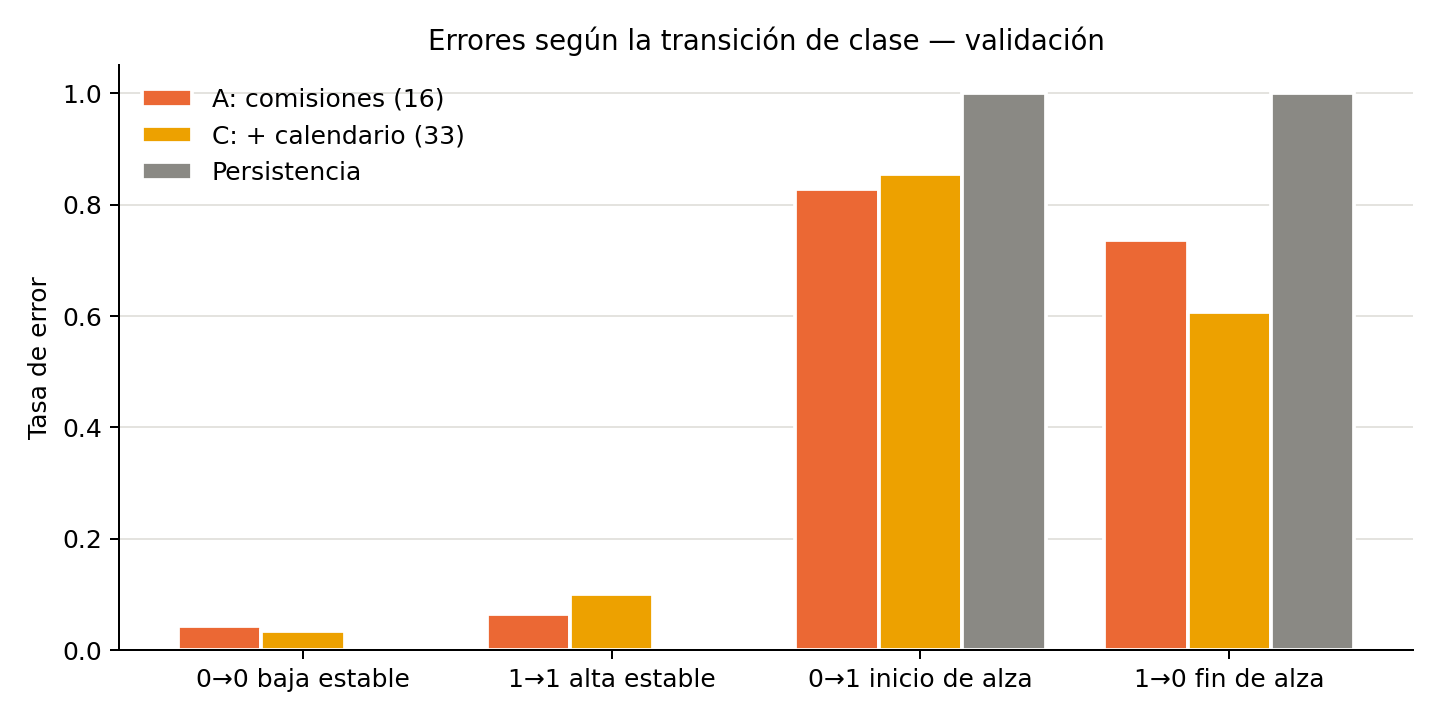

In [13]:
display(Image(FIGURAS / 'errores_por_transicion.png'))

**La clase cambia con mucha frecuencia.** Casi el 20 % de los bloques de validación son una transición (de baja a alta o al revés), y un episodio de comisión alta dura en promedio unos 2,2 bloques, es decir, poco más de veinte minutos. La persistencia falla exactamente en todas las transiciones y acierta en todos los tramos estables. Por eso es una referencia exigente y, a la vez, limitada.

Los modelos aprenden a **anticipar el final de un episodio** mejor que su inicio. El modelo C detecta el 39 % de los finales de alza (1→0), pero solo el 14 % de los inicios (0→1). A cambio, comete algunos errores en tramos estables (3,5 % en baja estable y 10 % en alta estable). El inicio de un episodio de comisiones altas corresponde a la llegada de demanda nueva que todavía no se refleja en los bloques ya minados, y eso es justo lo que el dataset no puede observar: el mempool.

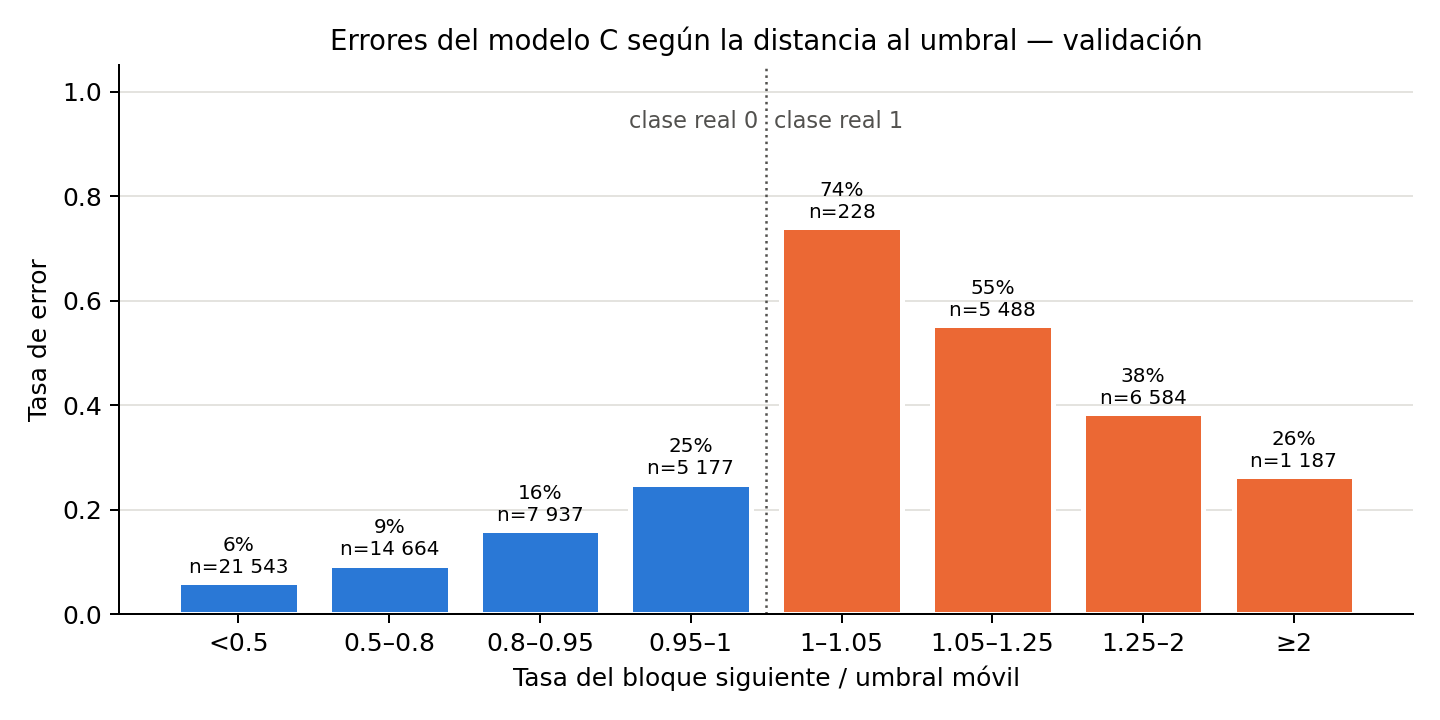

In [14]:
display(Image(FIGURAS / 'errores_por_margen.png'))

In [15]:
leer('errores_perfil_modeloC')

,tipo,n,fee_relativa,margen,cv_144,median_fee_rate,tx_count,size_relativo_1008,intervalo_segundos
0,VP,7441,1.3889,1.3810,0.4992,12.0,2443.0,0.6719,610.0
1,VN,44035,0.6000,0.5714,0.4973,4.0,1581.0,0.5974,392.0
2,FP,5286,1.1667,0.8000,0.4953,10.0,2442.5,0.6768,568.0
3,FN,6046,0.7000,1.2500,0.5009,5.0,1677.0,0.6277,342.0


**Los errores se concentran cerca del umbral.** El margen es la razón entre la tasa del bloque siguiente y el umbral móvil. Cuando el bloque siguiente está muy por debajo del umbral (margen < 0,5), el modelo C se equivoca solo el 6 % de las veces. Justo por encima del umbral (1–1,05), se equivoca el 74 %. Cuando el bloque siguiente es claramente caro (margen ≥ 2), el error baja al 26 %.

El perfil de los errores lo confirma:

- Los **falsos positivos** son bloques actuales caros (`fee_relativa` mediana 1,17) cuyo bloque siguiente termina algo por debajo del umbral (margen mediano 0,80).
- Los **falsos negativos** son bloques actuales baratos (`fee_relativa` 0,70) seguidos de un bloque que sí supera el umbral (margen 1,25).
- La volatilidad reciente (`cv_144`) es casi igual en los cuatro grupos: los errores no se explican por un régimen turbulento, sino por la cercanía al umbral y por los cambios de clase.

Los errores además se agrupan en el tiempo: la probabilidad de error dado un error en el bloque anterior es 0,40, frente a 0,18 en general, lo que refleja los episodios cortos descritos arriba.

## 5b. Comparación con las referencias oficiales (integrante 1)

Integrante 1 implementó la persistencia y la regresión logística con su propio conjunto de 22 variables (`fase2/integrante1/`). Sus resultados permiten situar los de este notebook:

| Método | Variables | F1 validación | AP validación | F1 prueba |
|---|---|---|---|---|
| Persistencia (integrante 1) | — | 0,5398 | — | 0,5763 |
| Regresión logística (integrante 1) | 22 | 0,5572 | 0,5929 | 0,5704 |
| HGB A0: tasa actual (este notebook) | 3 | 0,5387 | 0,5357 | no evaluado |
| HGB B: comisiones + actividad (este notebook) | 29 | 0,5727 | 0,6316 | no evaluado |
| HGB C: las 33 (este notebook) | 33 | 0,5677 | 0,6309 | no evaluado |

- **Persistencia.** Integrante 1 la define como `ŷ(t) = 1[tasa(t) > θ(t)]`; aquí se usa la clase observada del bloque actual, `ŷ(t) = y(t−1) = 1[tasa(t) > θ(t−1)]`. Ambas difieren solo en si el umbral incluye el bloque actual, y dan prácticamente el mismo F1 (0,5398 frente a 0,5400).
- **Regresión logística.** Su umbral de decisión se ajustó sobre validación, por lo que su F1 de validación es optimista frente al de los modelos de árboles, cuyo umbral se fijó con predicciones fuera de fold dentro de entrenamiento. Aun así, su AP en validación (0,593) queda por debajo de la de los conjuntos A, B y C (0,619–0,632).
- **Lectura conjunta.** En prueba, la logística no supera a la persistencia. El ablation explica por qué el margen es estrecho: el estado actual reproduce la persistencia, y la ganancia depende de capturar la historia de las comisiones de forma no lineal.
- **Calendario.** Integrante 1 observa coeficientes apreciables para la hora y el día en la logística. En el ablation, el calendario no añade nada una vez incluidas las medias móviles de 6 y 144 bloques, que ya recogen el ciclo diario. Además, parte de esa señal procede de la propia definición del umbral semanal, como advierte integrante 1.

## 6. Interpretación de conjunto

1. **La información útil está en la historia de las comisiones, no en el estado instantáneo.** El estado actual reproduce la persistencia; lo que añade valor son las medias, desviaciones y rezagos que describen la tendencia reciente del mercado. Esto concuerda con la importancia por impureza del Random Forest de integrante 2, donde `fee_relativa` y las medias móviles de la tasa encabezan la lista.
2. **La actividad de la red aporta poco porque, desde 2016, los bloques están casi siempre llenos.** Su tamaño y número de transacciones apenas varían, y la congestión se manifiesta en el precio, no en el volumen. Es el resultado que el EDA de P1 anticipaba con las correlaciones de `size` (0,002) y `tx_count` (0,11).
3. **El techo de rendimiento lo marca el propio target.** Con episodios de unos dos bloques y una frontera en el percentil 75 que se mueve en cada bloque, muchos ejemplos quedan a pocos satoshis del umbral. Ninguna variable de este dataset permite saber de qué lado caerán.
4. **La mejora sobre la persistencia es consistente pero modesta en F1** (+0,03 en validación, presente en todos los trimestres). En AP la diferencia es mayor, porque los modelos ordenan bien los bloques según su riesgo aunque el umbral binario recorte parte de esa ventaja.

## 7. Limitaciones

- **Sin mempool.** El dataset solo contiene bloques ya minados. La llegada de demanda nueva, que es lo que inicia un episodio de comisiones altas, no es observable. Es la principal razón de que los inicios de alza se detecten mal.
- **Target cercano al umbral.** Muchas etiquetas dependen de diferencias de uno o dos satoshis por byte respecto a un percentil móvil. Pequeños errores de medición de la fuente (el 0,31 % de los bloques tiene la mediana fuera del rango publicado) pueden cambiar la clase.
- **Validación tranquila.** El periodo de validación tiene pocos episodios de alta volatilidad, así que la evidencia sobre H3 es limitada. Los folds de entrenamiento cubren 2019–2021, pero participan en la selección del umbral.
- **Dependencia temporal.** Los bloques consecutivos no son independientes. El bootstrap por bloques semanales lo tiene en cuenta, pero los intervalos son aproximados y no se corrigen por comparaciones múltiples.
- **Un solo algoritmo en el ablation.** Las conclusiones sobre grupos de variables se obtienen con HistGradientBoosting y una configuración fija. Otro algoritmo podría aprovechar las variables de otra forma, aunque el Random Forest de integrante 2 apunta en la misma dirección.
- **Exposición previa del test.** P1 inspeccionó la proporción de clases en test para reformular el problema. Aquí no se usa test, pero esa exposición debe declararse en el informe.

## 8. Conclusiones provisionales

- **H1:** se confirma. La tasa reciente es el predictor dominante. Sin embargo, el estado actual por sí solo equivale a la persistencia; el valor aparece al incorporar la historia de las comisiones (+0,084 de AP).
- **H2:** se confirma. Las variables de actividad de la red aportan una mejora estadísticamente detectable pero pequeña (+0,012 de AP y +0,006 de F1), y el calendario no aporta nada adicional.
- **H3:** se confirma parcialmente. El rendimiento baja en el tercil de mayor volatilidad, pero de forma moderada. El patrón de error más claro no es la volatilidad, sino los cambios de clase: los modelos anticipan mal el inicio de los episodios de comisiones altas.

Estas conclusiones provienen de validación y se revisarán cuando el equipo congele el protocolo y evalúe el test una sola vez.